# LAB | Data Manipulation + JSON Handling
## Lab M1.02 - Data Manipulation + JSON Handling

**Titanic Data Analysis and JSON Export**

Delivered by Carolina Uchoa - 31 October, 2026

## Scenario:
You're working as a data analyst for a maritime safety research organization. Your team has been given access to the famous Titanic passenger dataset to analyze survival patterns. Your task is to clean the data, perform statistical analysis, engineer new features that might predict survival, and export the processed data to JSON format for use in other systems.

## What we will build:
-A data analysis script that processes the Titanic dataset
-Feature engineering functions that create new predictive variables
-A class-based system to structure and export data to JSON
-Statistical analysis comparing survival groups

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
from pathlib import Path
from datetime import datetime

#STEP 1 - Set up paths

DATA_DIR = Path("data")
CSV_FILE = DATA_DIR / "titanic.csv"
JSON_FILE = DATA_DIR / "titanic_data.json"

DATA_DIR.mkdir(exist_ok=True)
 
print("Project setup complete!")
print(f"Data directory: {DATA_DIR}")
print(f"CSV file location: {CSV_FILE}")

Matplotlib is building the font cache; this may take a moment.


Project setup complete!
Data directory: data
CSV file location: data/titanic.csv


In [30]:
#STEP 2 - Importing and Exploring the Data

df = pd.read_csv("titanic.csv")

print(f"Dataset loaded successfully! Shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")
print(f"\nFirst few rows:")
print(df.head())

Dataset loaded successfully! Shape: (891, 12)

Columns: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']

First few rows:
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 175

In [31]:
#STEP 3 - Calculating Descriptive Statistics
##Objective: Calculate mean, median, and standard deviation for numeric columns.

numeric_columns = df.select_dtypes(include="number").columns

print("MEAN:")
print(df[numeric_columns].mean())

print("\nMEDIAN:")
print(df[numeric_columns].median())

print("\nSTANDARD DEVIATION:")
print(df[numeric_columns].std())


MEAN:
PassengerId    446.000000
Survived         0.383838
Pclass           2.308642
Age             29.699118
SibSp            0.523008
Parch            0.381594
Fare            32.204208
dtype: float64

MEDIAN:
PassengerId    446.0000
Survived         0.0000
Pclass           3.0000
Age             28.0000
SibSp            0.0000
Parch            0.0000
Fare            14.4542
dtype: float64

STANDARD DEVIATION:
PassengerId    257.353842
Survived         0.486592
Pclass           0.836071
Age             14.526497
SibSp            1.102743
Parch            0.806057
Fare            49.693429
dtype: float64


In [35]:
#STEP 4 - Identifying Missing Values
##Objective: Count and analyze missing values in the dataset.

# Count missing values
print("\n" + "="*50)
print("MISSING VALUES ANALYSIS")
print("="*50)
 
missing_data = {}
 
for col in df.columns:
        missing_count = int(df[col].isna().sum())
        missing_percent = (missing_count / len(df)) * 100

        if missing_count > 0:
            missing_data[col] = {
                "count": missing_count,
                "percent": round(missing_percent, 2),
            }

        print(f"{col:10} {missing_count:4} missing ({missing_percent:.2f}%)")



MISSING VALUES ANALYSIS
PassengerId    0 missing (0.00%)
Survived      0 missing (0.00%)
Pclass        0 missing (0.00%)
Name          0 missing (0.00%)
Sex           0 missing (0.00%)
Age         177 missing (19.87%)
SibSp         0 missing (0.00%)
Parch         0 missing (0.00%)
Ticket        0 missing (0.00%)
Fare          0 missing (0.00%)
Cabin       687 missing (77.10%)
Embarked      2 missing (0.22%)


   SibSp  Parch  FamilySize
0      1      0           2
1      1      0           2
2      0      0           1
3      1      0           2
4      0      0           1
5      0      0           1
6      0      0           1
7      3      1           5
8      0      2           3
9      1      0           2
    Age     AgeGroup
0  22.0  Young Adult
1  38.0        Adult
2  26.0  Young Adult
3  35.0        Adult
4  35.0        Adult
5   NaN      Unknown
6  54.0       Senior
7   2.0        Child
8  27.0  Young Adult
9  14.0        Child
      Sex  IsFemale
0    male         0
1  female         1
2  female         1
3  female         1
4    male         0
5    male         0
6    male         0
7    male         0
8  female         1
9  female         1

FEATURE ANALYSIS: SURVIVED vs NOT SURVIVED

Family Size by Survival:
              mean  median       std
Survived                            
0         1.883424     1.0  1.830669
1         1.938596     2.0  1.186076

FEATURE ANALYSIS: SURV

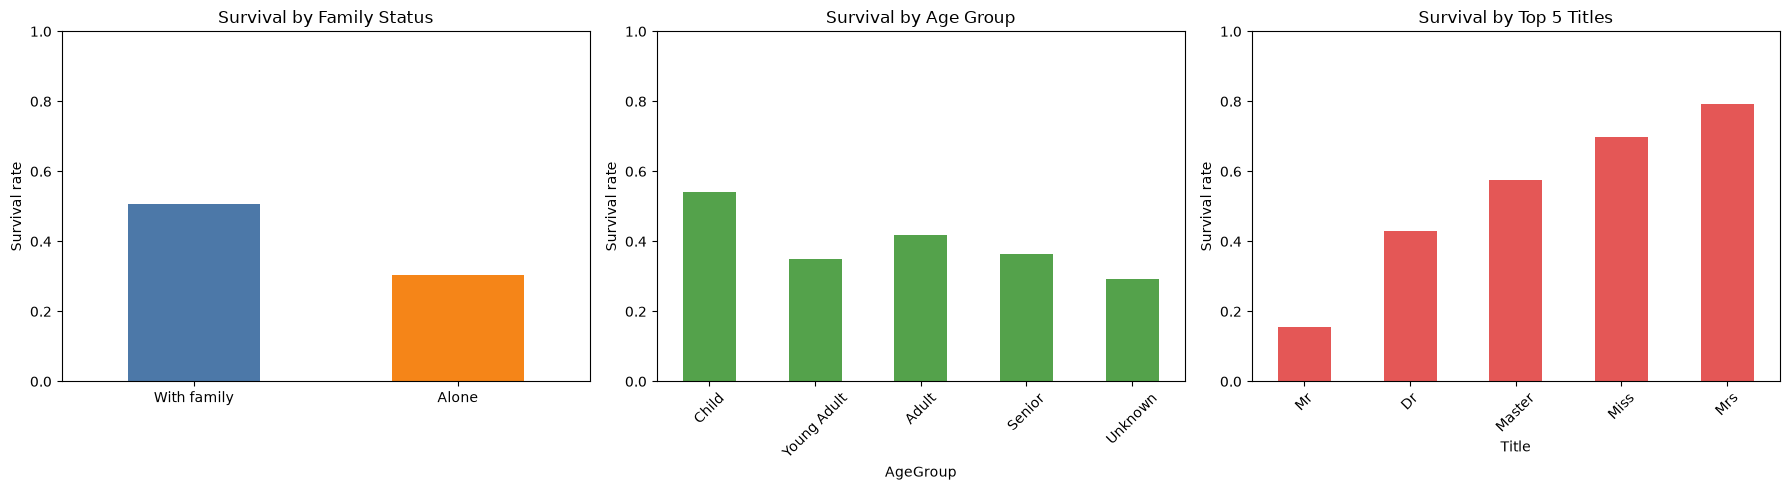

In [38]:
# STEP 5 - Feature Engineering
##Objective: Create new features that might help differentiate between surv

import matplotlib.pyplot as plt

# Create a copy of the dataframe for feature engineering
df_features = df.copy()
 
# Feature 1: Family Size
df_features['FamilySize'] = df_features["SibSp"] + df_features["Parch"] + 1 #the person
print(df_features[['SibSp', 'Parch', 'FamilySize']].head(10))
 
# Feature 2: Is Alone
df_features["IsAlone"] = ((df_features["SibSp"] + df_features["Parch"]) == 0).astype(int)

# Feature 3: Title

df_features["Title"] = df_features["Name"].str.extract(r",\s*([^.]*)\.", expand=False)
 
# Feature 4: Age Groups
def categorize_age(age):
    """Categorize age into groups"""
    if pd.isna(age):
        return 'Unknown'
    elif age < 18:
        return 'Child'
    elif age < 30:
        return 'Young Adult'
    elif age < 50:
        return 'Adult'
    else:
        return 'Senior'

df_features["AgeGroup"] = df_features["Age"].apply(categorize_age)
print(df_features[["Age", "AgeGroup"]].head(10))

# Feature 5: Sex

df_features['IsFemale'] = (df_features['Sex'] == 'female').astype(int)
print(df_features[['Sex', 'IsFemale']].head(10))

 
# Analyze feature differences between survivors and non-survivors
print("\n" + "="*50)
print("FEATURE ANALYSIS: SURVIVED vs NOT SURVIVED")
print("="*50)
 
# Here is an example to get you started:
print("\nFamily Size by Survival:")
family_survival = df_features.groupby('Survived')['FamilySize'].agg(['mean', 'median', 'std'])
print(family_survival)
 
# Statistical test: Do these features help differentiate?
print("\n" + "=" * 50)
print("FEATURE ANALYSIS: SURVIVED vs NOT SURVIVED")
print("=" * 50)
 
print("\nFamily Size by Survival:")
print(df_features.groupby("Survived")["FamilySize"].agg(["mean", "median", "std"]))
 
print("\nSurvival rate: alone (1) vs with family (0):")
print(df_features.groupby("IsAlone")["Survived"].mean().round(2))
 
print("\nSurvival rate by Age Group:")
print(df_features.groupby("AgeGroup")["Survived"].mean().round(2))
 
print("\nSurvival rate by Title (top 5 titles):")
top_titles = df_features["Title"].value_counts().head(5).index
print(df_features[df_features["Title"].isin(top_titles)].groupby("Title")["Survived"].mean().round(2))
 
survived = df_features[df_features["Survived"] == 1]
not_survived = df_features[df_features["Survived"] == 0]
 
print("\nFamily Size:")
print(f"  Survived mean: {survived['FamilySize'].mean():.2f}")
print(f"  Not Survived mean: {not_survived['FamilySize'].mean():.2f}")
print(f"  Difference: {abs(survived['FamilySize'].mean() - not_survived['FamilySize'].mean()):.2f}")
 
df_engineered = df_features

# Visual comparison of survival rates across engineered features
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

alone_rates = df_features.groupby("IsAlone")["Survived"].mean()
alone_rates.index = ["With family", "Alone"]
alone_rates.plot(kind="bar", ax=axes[0], color=["#4C78A8", "#F58518"])
axes[0].set_title("Survival by Family Status")
axes[0].set_ylabel("Survival rate")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=0)

age_order = ["Child", "Young Adult", "Adult", "Senior", "Unknown"]
age_rates = df_features.groupby("AgeGroup")["Survived"].mean().reindex(age_order).dropna()
age_rates.plot(kind="bar", ax=axes[1], color="#54A24B")
axes[1].set_title("Survival by Age Group")
axes[1].set_ylabel("Survival rate")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=45)

title_rates = df_features.groupby("Title")["Survived"].mean().loc[top_titles].sort_values()
title_rates.plot(kind="bar", ax=axes[2], color="#E45756")
axes[2].set_title("Survival by Top 5 Titles")
axes[2].set_ylabel("Survival rate")
axes[2].set_ylim(0, 1)
axes[2].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


**Checkpoint: Verify that your engineered features are created correctly and show meaningful differences between survival groups. Can you think about any other new feature? What insights do these features provide?**

We can notice that people the FamilySize barely differs between groups (1.94 vs 1.88), but IsAlone and IsFemale show strong differences: people alone and men had much lower survival rates.

In [41]:
import json
from datetime import datetime
from pathlib import Path

# STEP 6 - Creating Classes for JSON Export 
## Create a Python class to structure and export data to JSON format.
 
class Passenger: #all the information
    def __init__(self, passenger_id, name, age, sex, survived, pclass, fare, embarked=None, family_size=None, is_alone=None, age_group=None, title=None):
        self.passenger_id = int(passenger_id) if pd.notna(passenger_id) else None
        self.name = str(name) if pd.notna(name) else None
        self.age = float(age) if pd.notna(age) else None
        self.sex = str(sex) if pd.notna(sex) else None
        self.survived = int(survived) if pd.notna(survived) else None
        self.pclass = int(pclass) if pd.notna(pclass) else None
        self.fare = float(fare) if pd.notna(fare) else None
        self.embarked = str(embarked) if pd.notna(embarked) else None
        self.family_size = int(family_size) if pd.notna(family_size) else None
        self.is_alone = bool(is_alone) if pd.notna(is_alone) else None
        self.age_group = str(age_group) if pd.notna(age_group) else None
        self.title = str(title) if pd.notna(title) else None


    
    def to_dict(self): #convert passenger to dictionary for JSON
        return {
            'passenger_id': self.passenger_id,
            'name': self.name,
            'age': self.age,
            'sex': self.sex,
            'survived': self.survived,
            'pclass': self.pclass,
            'fare': self.fare,
            'embarked': self.embarked,
            'family_size': self.family_size,
            'is_alone': self.is_alone,
            'age_group': self.age_group,
            'title': self.title
            }


class TitanicDataset: #entire titanic datased with methods for JSON export
    def __init__(self, dataframe):
        self.dataframe = dataframe
        self.passengers = []  # Will store Passenger objects
        self._create_passengers()
    
    def _create_passengers(self):
        for idx, row in self.dataframe.iterrows():
            passenger = Passenger(
                passenger_id=row.get("PassengerId", idx),
                name=row.get("Name"),
                age=row.get("Age"),
                sex=row.get("Sex"),
                survived=row.get("Survived"),
                pclass=row.get("Pclass"),
                fare=row.get("Fare"),
                embarked=row.get("Embarked"),
                family_size=row.get("FamilySize"),
                is_alone=row.get("IsAlone"),
                age_group=row.get("AgeGroup"),
                title=row.get("Title"),
            )
            self.passengers.append(passenger)
    
    def get_summary_stats(self):
        ages = [p.age for p in self.passengers if p.age is not None]
        fares = [p.fare for p in self.passengers if p.fare is not None]

        return {
            'total_passengers': len(self.passengers),
            'survived': sum(1 for p in self.passengers if p.survived == 1),
            'did_not_survive': sum(1 for p in self.passengers if p.survived == 0),
            'average_age': round(sum(ages) / len(ages), 2),
            'average_fare': round(sum(fares) / len(fares), 2),
        }

    def to_json(self, filename='titanic_data.json'):
        data = {
            "metadata": {
                "dataset_name": "Titanic Passenger Dataset",
                "export_date": datetime.now().isoformat(),
                "total_passengers": len(self.passengers),
                "survival_rate": round(float(self.dataframe["Survived"].mean()), 4),
            },
            "summary_stats": self.get_summary_stats(),
            "descriptive_statistics": self.dataframe.select_dtypes(include="number").describe().to_dict(),
            "missing_values": missing_data,
            "passengers": [p.to_dict() for p in self.passengers],
        }
        with open(filename, "w", encoding="utf-8") as f:
            json.dump(data, f, indent=2, ensure_ascii=False)
        print(f"Data exported to {filename}")
        return data
 
 
if "df_engineered" in locals() and not df_engineered.empty:
    dataset = TitanicDataset(df_engineered)
 
    print("\n" + "=" * 50)
    print("DATASET SUMMARY")
    print("=" * 50)
    print(f"Passenger objects created: {len(dataset.passengers)}")
    for key, value in dataset.get_summary_stats().items():
        print(f"  {key}: {value}")
    dataset.to_json(JSON_FILE)



DATASET SUMMARY
Passenger objects created: 891
  total_passengers: 891
  survived: 342
  did_not_survive: 549
  average_age: 29.7
  average_fare: 32.2
Data exported to data/titanic_data.json


In [44]:
#STEP 7 - Testing and Validation

print("\n" + "=" * 50)
print("JSON VALIDATION")
print("=" * 50)

with open(JSON_FILE, "r", encoding="utf-8") as f:
    json_data = json.load(f)

print(f"Top-level keys: {list(json_data.keys())}")
print(f"Number of passenger records: {len(json_data['passengers'])}")
assert len(json_data["passengers"]) == len(df), "Passenger count does not match!"
assert "metadata" in json_data and "missing_values" in json_data
print("First passenger:", json_data["passengers"][0])
print("JSON validation passed!")




JSON VALIDATION
Top-level keys: ['metadata', 'summary_stats', 'descriptive_statistics', 'missing_values', 'passengers']
Number of passenger records: 891
First passenger: {'passenger_id': 1, 'name': 'Braund, Mr. Owen Harris', 'age': 22.0, 'sex': 'male', 'survived': 0, 'pclass': 3, 'fare': 7.25, 'embarked': 'S', 'family_size': 2, 'is_alone': False, 'age_group': 'Young Adult', 'title': 'Mr'}
JSON validation passed!


**A brief explanation (2-3 sentences) describing:**

## Which engineered features you created:
Four new features: FamilySize (SibSp + Parch + 1), IsAlone (1 if the passenger travelled without the family), AgeGroup (Child, Young Adult, Adult, Senior or Unknown), and IsFemale (1 for women and 0 for men)

## How these features help differentiate between survivors and non-survivors
The features can show clear patterns: passengers travelling alone survived much less, children had the highest survival rate, and women survived more than man.

## What you learned about using classes for data processing
Using classes and titanic dataset helped organize the data, being able to transform each passenger to a consistent object and create a logic for calculation and exporting to JSON.

